# Julia から Wolfram Engine を呼び出す — 数列・和・極限を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します（積分編・微分編・方程式編の続き）。

- 和 `Sum` → $\sum$ の公式（$n$ の式）を **Julia の関数**にし，ループで足した値と照合する
- 漸化式 `RSolve` → 一般項を **Julia の関数**にし，漸化式どおりに計算した値と照合する
- 極限 `Limit` → **厳密値**を受け取り，数値実験と比べる
- 無限級数 → **厳密な和**（$\frac{\pi^2}{6}$ など）を受け取り，部分和の収束を見る
- 数式は $\LaTeX$ 組版（TraditionalForm 相当）で表示する

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。初回だけパッケージを追加します（追加済みなら次のセルは実行不要）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "SpecialFunctions", "Plots"])
# Pkg.add(url="https://github.com/ujimushi/PlotsGRBackendFontJaEmoji.jl")   # グラフの日本語表示用

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

## 1. 基本：`Sum`，`Limit`，`RSolve`

In [3]:
weval(W`Sum[k^2, {k, 1, n}]`)

W`Times[Rational[1, 6], n, Plus[1, n], Plus[1, Times[2, n]]]`

In [4]:
weval(W`Limit[(1 + 1/n)^n, n -> Infinity]`)

W"E"

In [5]:
weval(W`RSolve[{a[n + 1] == 2 a[n] + 1, a[1] == 1}, a[n], n]`)      # a(n) → 一般項 という規則が返る

W`List[List[Rule[a[n], Plus[-1, Power[2, n]]]]]`

## 2. きれいに表示するための関数

`calc("Wolfram の式")` は，入力した式（$\sum$ や $\lim$ の形のまま）と評価結果を「左辺 = 右辺」で表示し，結果を返します。

In [6]:
# TeXForm の出力を見やすく整える（lim の書き方，日本語化）
function jtex(s)
    s = replace(s, r"\\underset\{(.*?)\}\{\\text\{lim\}\}" => s"\\lim_{\1}")
    replace(s, "\\text{Indeterminate}" => "\\text{極限なし}",
               "\\text{True}" => "\\text{収束}", "\\text{False}" => "\\text{発散}")
end

# Wolfram 言語の文字列 → 評価せずに LaTeX 文字列（入力した形のまま表示する）
texheld(s::AbstractString) = jtex(heldtex(s))

# 評価されずに戻ってきたか（発散する，閉じた式がない，など）
unevaluated(w) = w isa MathLink.WExpr && w.head isa MathLink.WSymbol &&
                 w.head.name in ("Sum", "Product", "Limit", "RSolve")

# 「入力した式 = 評価結果」を表示して，結果（Wolfram の式）を返す
function calc(cmd::AbstractString; simplify=false)
    res = weval(MathLink.parseexpr(cmd))
    if unevaluated(res)
        showtex(texheld(cmd) * "\\quad\\text{は求められません（発散する，または閉じた式がない）}")
        return res
    end
    simplify && (res = weval(W"FullSimplify"(res)))
    showtex(texheld(cmd) * " = " * jtex(tex(res)))
    return res
end

calc (generic function with 1 method)

In [7]:
calc("Sum[k^2, {k, 1, n}]")
calc("Limit[(1 + 1/n)^n, n -> Infinity]")
calc("Sum[1/k^2, {k, 1, Infinity}]");

## 3. Wolfram の式を Julia の式・関数に変換する

変換の関数は，共通ファイル `wolfram_common.jl` にまとめてあります（0 節の `include` で読み込み済み）。

- `to_expr(w)`：Wolfram の式 → Julia の式（`Expr`）
- `to_value(w)`：Wolfram の式 → Julia の値
- `to_function(w, :x, ...)`：Wolfram の式 → Julia の関数
- 対応表 `WFUNC`（Wolfram の関数名 → Julia の関数名）に無い関数が出てきたら，`WFUNC["名前"] = :Juliaの関数名` で追加できます。

このノートブックで特に使う変換：

- **整数 $n$ を入れたら厳密な値が返る**：$2^{-n}$ や $\frac{1}{n+1}$ は，整数 $n$ に対して `Rational`（分数）で計算する（`pw` 関数）。結果が整数になれば `Int` に直す
- $\infty$ → `Inf`，極限なし（`Indeterminate`）→ `NaN`
- 調和数 $H_n$ → `harmonic(n)`，フィボナッチ数 $F_n$ → `fibonacci(n)`，二項係数，階乗

## 4. 数列の項を並べる

`Table` で作った項のリストは，Julia の配列になります（分数は `Rational` のまま厳密）。

In [8]:
tw = weval(W`Table[1/(n (n + 1)), {n, 1, 8}]`)
showtex("a_n = \\frac{1}{n(n+1)}:\\quad " * tex(tw))

terms = to_value(tw)

8-element Vector{Rational{Int64}}:
 1//2
 1//6
 1//12
 1//20
 1//30
 1//42
 1//56
 1//72

In [9]:
sum(terms), cumsum(terms)            # Julia 側で和・部分和（分数のまま厳密）

(8//9, Rational{Int64}[1//2, 2//3, 3//4, 4//5, 5//6, 6//7, 7//8, 8//9])

## 5. 和の公式 → Julia の関数

$\sum$ を $n$ の式で求め，Julia の関数 `S(n)` にします。

In [10]:
Sw = calc("Sum[k^2, {k, 1, n}]")
S  = to_function(Sw, :n)
to_expr(Sw)

:(1 // 6 * n * (1 + n) * (1 + 2n))

**検算**：Julia で実際に足した値と比べます。

In [11]:
for n in (1, 2, 3, 10, 100, 1000)
    println("n = $n :  公式  ", S(n), "    足し算  ", sum(k^2 for k in 1:n))
end

n = 1 :  公式  1    足し算  1
n = 2 :  公式  5    足し算  5
n = 3 :  公式  14    足し算  14
n = 10 :  公式  385    足し算  385
n = 100 :  公式  338350    足し算  338350
n = 1000 :  公式  333833500    足し算  333833500


In [12]:
all(S(n) == sum(k^2 for k in 1:n) for n in 1:500)       # n = 1〜500 ですべて一致するか

true

### いろいろな和

In [13]:
calc("Sum[k, {k, 1, n}]")
calc("Sum[k^3, {k, 1, n}]")
calc("Sum[2k - 1, {k, 1, n}]")
calc("Sum[r^(k - 1), {k, 1, n}]")                 # 等比数列の和
calc("Sum[k 2^k, {k, 1, n}]")                     # （等差）×（等比）
calc("Sum[1/(k (k + 1)), {k, 1, n}]")             # 部分分数分解で消える和
calc("Sum[1/(k (k + 1)), {k, 1, n}]"; simplify=true)
calc("Sum[Binomial[n, k], {k, 0, n}]")
calc("Sum[1/k, {k, 1, n}]");                      # 閉じた式はなく，調和数 H_n という名前で返る

整数 $n$ を入れると，分数の和も**厳密な分数**で返ります。

In [14]:
T = to_function(weval(W`Sum[1/(k (k + 1)), {k, 1, n}]`), :n)
G = to_function(weval(W`Sum[(1/2)^k, {k, 1, n}]`), :n)

@show T(10) sum(1 // (k * (k + 1)) for k in 1:10)
@show G(10) sum((1 // 2)^k for k in 1:10)
@show T(10.0);                        # 小数を入れれば小数で返る

T(10) = 10//11
sum((1 // (k * (k + 1)) for k = 1:10)) = 10//11
G(10) = 1023//1024
sum(((1 // 2) ^ k for k = 1:10)) = 1023//1024
T(10.0) = 0.9090909090909091


文字 $r$ を含む和は 2 変数の関数にできます。

In [15]:
geo = to_function(weval(W`Sum[a r^(k - 1), {k, 1, n}]`), :a, :r, :n)      # 初項 a，公比 r，項数 n
geo(3, 2, 10), sum(3 * 2^(k - 1) for k in 1:10)

(3069, 3069)

**大きな $n$ では `big(n)` を使う**：`Int` は $2^{63}$ 以上を表せないので，桁あふれします。

In [16]:
P = to_function(weval(W`Sum[2^k, {k, 0, n}]`), :n)
P(10), P(big(100))

(2047, 2535301200456458802993406410751)

## 6. 漸化式 → 一般項を Julia の関数にする

`rsolve([漸化式, 初期条件, ...])` にまとめます。数列は `a[n]` と書きます。  
戻り値は `(Wolfram の式, Julia の関数)` です。

In [17]:
# TeX の a(n+1) を a_{n+1} に書き換える
sub(s, a="a") = replace(s, Regex("$a\\((.*?)\\)") => SubstitutionString("$(a)_{\\1}"))

function rsolve(eqs::Vector{String}; a="a", n="n", simplify=true)
    res = weval(MathLink.parseexpr("$a[$n] /. First[RSolve[{$(join(eqs, ", "))}, $a[$n], $n]]"))
    occursin("RSolve", string(res)) && error("RSolve では一般項を求められませんでした。")
    simplify && (res = weval(W"FullSimplify"(res)))
    showtex(join(sub.(texheld.(eqs), a), ",\\quad ") * "\\implies $(a)_{$n} = " * tex(res))
    return res, to_function(res, Symbol(n))
end

rsolve (generic function with 1 method)

In [18]:
aw, a = rsolve(["a[n + 1] == 2 a[n] + 1", "a[1] == 1"])
a.(1:10)                              # 一般項で計算した最初の 10 項

10-element Vector{Int64}:
    1
    3
    7
   15
   31
   63
  127
  255
  511
 1023

**検算**：漸化式どおりに Julia で順に計算した値と比べます。

In [19]:
# 漸化式 a_{n+1} = step(a_n, n) を初項 a1 から N 項まで計算する
function iterate_seq(step, a1, N)
    seq = [a1]
    for n in 1:N-1
        push!(seq, step(seq[end], n))
    end
    return seq
end

iterate_seq((an, n) -> 2an + 1, 1, 10)

10-element Vector{Int64}:
    1
    3
    7
   15
   31
   63
  127
  255
  511
 1023

In [20]:
a.(1:10) == iterate_seq((an, n) -> 2an + 1, 1, 10)

true

### いろいろな漸化式

In [21]:
_, a1 = rsolve(["a[n + 1] == a[n] + 2n", "a[1] == 1"])               # 階差数列
_, a2 = rsolve(["a[n + 1] == 3 a[n] - 4", "a[1] == 3"])              # a_{n+1} = p a_n + q
_, a3 = rsolve(["a[n + 1] == a[n]/2 + 1", "a[1] == 0"])              # 収束する数列
_, a4 = rsolve(["a[n + 1] == a[n]/(1 + a[n])", "a[1] == 1"])         # 分数型
_, a5 = rsolve(["a[n + 2] == 5 a[n + 1] - 6 a[n]", "a[1] == 1", "a[2] == 5"]);   # 隣接 3 項間

In [22]:
# 一般項と，漸化式どおりの計算が一致するか（分数は // で厳密に計算する）
println(a1.(1:8) == iterate_seq((an, n) -> an + 2n, 1, 8))
println(a2.(1:8) == iterate_seq((an, n) -> 3an - 4, 3, 8))
println(a3.(1:8) == iterate_seq((an, n) -> an // 2 + 1, 0 // 1, 8))
println(a4.(1:8) == iterate_seq((an, n) -> an // (1 + an), 1 // 1, 8))
a3.(1:8)                              # 分数のまま厳密

true
true
true
true


8-element Vector{Real}:
    0
    1
   3//2
   7//4
  15//8
  31//16
  63//32
 127//64

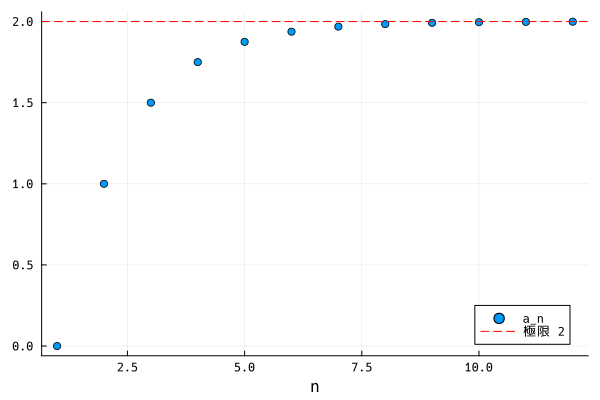

In [23]:
# 収束のようす：a_{n+1} = a_n/2 + 1 は 2 に近づく
calc("Limit[2 - 2^(2 - n), n -> Infinity]")
scatter(1:12, float.(a3.(1:12)); label="a_n", xlabel="n")
hline!([2]; color=:red, ls=:dash, label="極限 2", legend=:bottomright)

### フィボナッチ数列

$a_{n+2} = a_{n+1} + a_n$ は，Wolfram では $F_n$（`Fibonacci[n]`）という名前で返ります。  
隣り合う項の比の極限は黄金比 $\frac{1+\sqrt5}{2}$ です。

In [24]:
_, fib = rsolve(["a[n + 2] == a[n + 1] + a[n]", "a[1] == 1", "a[2] == 1"])
fib.(1:15)

15-element Vector{Int64}:
   1
   1
   2
   3
   5
   8
  13
  21
  34
  55
  89
 144
 233
 377
 610

In [25]:
φw = calc("Limit[Fibonacci[n + 1]/Fibonacci[n], n -> Infinity]")
φ  = to_value(φw)

for n in (5, 10, 20, 40)
    println("n = $n :  F(n+1)/F(n) = ", fib(n + 1) / fib(n), "    誤差 ", fib(n + 1) / fib(n) - φ)
end

n = 5 :  F(n+1)/F(n) = 1.6    誤差 -0.018033988749894814
n = 10 :  F(n+1)/F(n) = 1.6181818181818182    誤差 0.00014782943192326314
n = 20 :  F(n+1)/F(n) = 1.6180339985218033    誤差 9.771908393574336e-9
n = 40 :  F(n+1)/F(n) = 1.618033988749895    誤差 0.0


### 項から一般項を推測する

`FindSequenceFunction` は，並んだ項から規則を推測します（推測なので，正しい保証はありません）。

In [26]:
gw = weval(W`FindSequenceFunction[{1, 3, 7, 15, 31, 63}, n]`)
showtex("1,\\ 3,\\ 7,\\ 15,\\ 31,\\ 63,\\ \\dots \\implies a_n = " * tex(gw))

hw = weval(W`FindSequenceFunction[{2, 6, 12, 20, 30, 42}, n]`)
showtex("2,\\ 6,\\ 12,\\ 20,\\ 30,\\ 42,\\ \\dots \\implies a_n = " * tex(hw))

to_function(hw, :n).(1:10)

10-element Vector{Int64}:
   2
   6
  12
  20
  30
  42
  56
  72
  90
 110

## 7. 極限

`Limit` は厳密な極限値を返します。$\infty$ は Julia の `Inf`，極限が存在しないときは `NaN` になります。

In [27]:
L1 = calc("Limit[(3n^2 + 1)/(n^2 + n), n -> Infinity]")
L2 = calc("Limit[Sqrt[n^2 + n] - n, n -> Infinity]")
L3 = calc("Limit[(1 + 1/n)^n, n -> Infinity]")
L4 = calc("Limit[n^2, n -> Infinity]")
L5 = calc("Limit[(-1)^n, n -> Infinity]")

to_value.([L1, L2, L3, L4, L5])

5-element Vector{Real}:
   3
  1//2
   ℯ = 2.7182818284590...
  Inf
 NaN

**数値実験と比べる**：$\left(1+\frac1n\right)^n$ が $e$ に近づくようすを見ます。

In [28]:
e_seq(n) = (1 + 1 / n)^n
for n in (1, 10, 100, 1000, 10^4, 10^6)
    println("n = $n :  ", e_seq(n), "    e との差 ", to_value(L3) - e_seq(n))
end

n = 1 :  2.0    e との差 0.7182818284590451
n = 10 :  2.5937424601000023    e との差 0.12453936835904278
n = 100 :  2.7048138294215285    e との差 0.01346799903751661
n = 1000 :  2.7169239322355936    e との差 0.0013578962234515046
n = 10000 :  2.7181459268249255    e との差 0.000135901634119584
n = 1000000 :  2.7182804690957534    e との差 1.359363291708604e-6


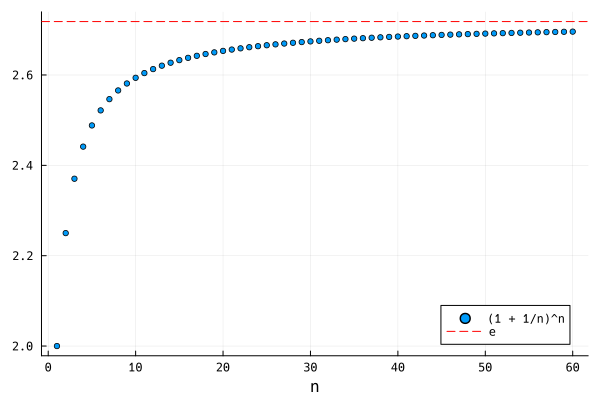

In [29]:
ns = 1:60
scatter(ns, e_seq.(ns); label="(1 + 1/n)^n", xlabel="n", ms=3)
hline!([to_value(L3)]; color=:red, ls=:dash, label="e", legend=:bottomright)

### 関数の極限・片側極限

In [30]:
calc("Limit[Sin[x]/x, x -> 0]")
calc("Limit[(1 - Cos[x])/x^2, x -> 0]")
calc("Limit[(Exp[x] - 1)/x, x -> 0]")
calc("Limit[(Sqrt[1 + x] - 1)/x, x -> 0]")
calc("Limit[x Log[x], x -> 0, Direction -> \"FromAbove\"]")
calc("Limit[1/x, x -> 0, Direction -> \"FromAbove\"]")      # 右側極限
calc("Limit[1/x, x -> 0, Direction -> \"FromBelow\"]")      # 左側極限
calc("Limit[1/x, x -> 0]");                                  # 左右で異なるので極限なし

In [31]:
# 数値で確かめる：(1 - cos x)/x² → 1/2
g(x) = (1 - cos(x)) / x^2
[(x, g(x)) for x in (1.0, 0.1, 0.01, 0.001)]

4-element Vector{Tuple{Float64, Float64}}:
 (1.0, 0.45969769413186023)
 (0.1, 0.49958347219741783)
 (0.01, 0.4999958333473664)
 (0.001, 0.49999995832550326)

## 8. 無限級数

`Sum[..., {k, 1, Infinity}]` は無限級数の和を厳密に返します。

In [32]:
B  = calc("Sum[1/k^2, {k, 1, Infinity}]")               # バーゼル問題
calc("Sum[(1/2)^k, {k, 1, Infinity}]")
calc("Sum[9/10^k, {k, 1, Infinity}]")                   # 0.999... = 1
calc("Sum[1/(k (k + 1)), {k, 1, Infinity}]")
calc("Sum[1/k!, {k, 0, Infinity}]")
calc("Sum[(-1)^(k + 1)/k, {k, 1, Infinity}]")
calc("Sum[(-1)^k/(2k + 1), {k, 0, Infinity}]")          # ライプニッツの級数
calc("Sum[r^k, {k, 0, Infinity}]");                     # 無限等比級数（|r| < 1 のとき）

**部分和の収束**：$\displaystyle\sum_{k=1}^{n}\frac1{k^2}$ が $\dfrac{\pi^2}{6}$ に近づくようすを見ます。

basel = 1.6449340668482262
π ^ 2 / 6 = 1.6449340668482264


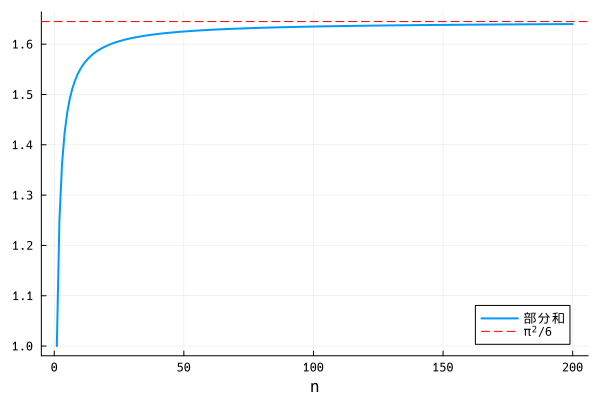

In [33]:
basel = to_value(B)
partial = cumsum(1 / k^2 for k in 1:200)

@show basel π^2 / 6
plot(partial; label="部分和", xlabel="n", lw=2)
hline!([basel]; color=:red, ls=:dash, label="π²/6", legend=:bottomright)

### 収束・発散の判定

発散する級数は `Sum` が未評価のまま返ります（Wolfram の警告が出ます）。`SumConvergence` で判定だけすることもできます。

In [34]:
calc("Sum[1/k, {k, 1, Infinity}]");                     # 調和級数は発散

┌ Warning: Sum::div: Sum does not converge.
└ @ MathLink ~/.julia/packages/MathLink/WEvUg/src/eval.jl:16


In [35]:
# 一般項 term の級数が収束するかを判定する（true / false を返す）
function converges(term::AbstractString, k="k")
    res = weval(MathLink.parseexpr("SumConvergence[$term, $k]"))
    showtex("\\sum_{$k}\\ " * texheld(term) * "\\quad\\text{は}\\ " * jtex(tex(res)))
    return to_value(res)
end

converges("1/k")
converges("1/k^2")
converges("1/(k Log[k])")
converges("(-1)^k/Sqrt[k]")

true

In [36]:
# 調和級数の部分和 H_n はゆっくり発散する（log n + γ に近い）
H = to_function(weval(W`Sum[1/k, {k, 1, n}]`), :n)
γ = to_value(calc("Limit[HarmonicNumber[n] - Log[n], n -> Infinity]"))      # オイラーの定数

@show H(10)                           # 整数 n では厳密な分数
for n in (10, 100, 1000)              # 分母が巨大になるので big(n) を使う
    println("n = $n :  H_n = ", Float64(H(big(n))), "    log n + γ = ", log(n) + γ)
end

H(10) = 7381//2520
n = 10 :  H_n = 2.9289682539682538    log n + γ = 2.8798007578955787
n = 100 :  H_n = 5.187377517639621    log n + γ = 5.182385850889625
n = 1000 :  H_n = 7.485470860550345    log n + γ = 7.48497094388367


### 積 `Product`

In [37]:
Pw = calc("Product[1 - 1/k^2, {k, 2, n}]")
calc("Product[1 - 1/k^2, {k, 2, Infinity}]")

Pn = to_function(Pw, :n)
Pn(10), prod(1 - 1 // k^2 for k in 2:10)

(11//20, 11//20)

## 9. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **「求められません」と表示される**：和が発散する，または閉じた式がない場合です。`SumConvergence` で収束を確認するか，Julia 側で数値的に計算します。
- **大きな $n$ でおかしな値・`OverflowError`**：`Int` の桁あふれです。`S(big(100))` のように `big` を付けます。
- **未対応の関数が出た**：エラーメッセージに出た名前を `WFUNC` に追加します。
- **漸化式の添字**：`a[n + 1]` のように角かっこで書きます。等号は `==` です。

In [38]:
# 閉じた式がない例：結果を Julia の関数にしようとするとエラーで知らせる
uw = calc("Sum[1/(k^k), {k, 1, n}]")
try
    to_function(uw, :n)
catch e
    println(e.msg)
end

Wolfram が閉じた式で求められませんでした（発散する，解けない，など）: W`Sum[Power[k, Times[-1, k]], List[k, 1, n]]`
